In [ ]:
# ═══════════════════════════════════════════════════════════════
# WEEKS 4-6: PX4 Logs + TEXBAT + SITL + Physics ODE
# ═══════════════════════════════════════════════════════════════
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd

drive_base = "/content/drive/MyDrive/uav-spoof-ids/"

# Create week 4-6 folder structure
for folder in [
    "data/raw/px4_logs",
    "data/raw/sitl",
    "data/processed/px4",
    "data/processed/sitl",
    "src/physics",
    "results/week4_6",
]:
    os.makedirs(drive_base + folder, exist_ok=True)

print("Folders created. Week 4-6 ready.")

Mounted at /content/drive
Folders created. Week 4-6 ready.


In [ ]:
import scipy.io
import pandas as pd
import numpy as np

drive_base = "/content/drive/MyDrive/uav-spoof-ids/"
texbat_out = drive_base + "data/raw/texbat/processed/"

# Confirmed correct column mapping from week 1-3 analysis
channel_cols = [
    'unknown_0', 'RX_time_s', 'GPS_TOW_s', 'carrier_phase_cyc',
    'clock_bias_s', 'doppler_hz', 'vel_component', 'pseudorange_m',
    'CN0_dBHz', 'lock_indicator', 'cycle_slip', 'channel_num',
    'PRN', 'lock_time_s'
]
navsol_cols = [
    'GPS_week', 'GPS_TOW_s', 'clock_bias_s', 'pos_x_m',
    'pos_y_m', 'pos_z_m', 'clock_drift_ms', 'pdop',
    'num_sv', 'vel_x_ms', 'vel_y_ms', 'vel_z_ms'
]

dataset_info = {
    'cleanStatic': {'label': 0, 'spoof_type': 'none',         'path': texbat_out + 'cleanStatic/'},
    'ds2':         {'label': 1, 'spoof_type': 'slow_drift',    'path': texbat_out + 'ds2/'},
    'ds3':         {'label': 1, 'spoof_type': 'faster_drift',  'path': texbat_out + 'ds3/'},
    'ds7':         {'label': 1, 'spoof_type': 'SCER',          'path': texbat_out + 'ds7/'},
}

def load_texbat_scenario(ds_name, info):
    ch_arr  = np.array(scipy.io.loadmat(
        info['path'] + 'channel.mat')['channel']).T
    nav_arr = np.array(scipy.io.loadmat(
        info['path'] + 'navsol.mat')['navsol']).T

    df_ch  = pd.DataFrame(ch_arr,
                          columns=channel_cols[:ch_arr.shape[1]])
    df_nav = pd.DataFrame(nav_arr,
                          columns=navsol_cols[:nav_arr.shape[1]])

    # Keep only physically meaningful GPS signal features
    gps_features = ['RX_time_s', 'PRN', 'CN0_dBHz', 'doppler_hz',
                    'pseudorange_m', 'carrier_phase_cyc',
                    'clock_bias_s', 'lock_time_s', 'cycle_slip']
    df_ch = df_ch[gps_features].copy()

    # Merge nav solution on time (nearest match)
    df_ch  = df_ch.sort_values('RX_time_s').reset_index(drop=True)
    df_nav = df_nav.sort_values('GPS_TOW_s').reset_index(drop=True)

    # Add nav-level features: clock drift, num_sv, position
    df_nav_sub = df_nav[['GPS_TOW_s', 'clock_drift_ms',
                          'num_sv', 'pdop',
                          'pos_x_m', 'pos_y_m', 'pos_z_m']].copy()

    # Align by nearest timestamp
    df_ch['GPS_TOW_s'] = df_ch['RX_time_s']
    df_merged = pd.merge_asof(
        df_ch.sort_values('GPS_TOW_s'),
        df_nav_sub.sort_values('GPS_TOW_s'),
        on='GPS_TOW_s', direction='nearest'
    )

    # Add metadata
    df_merged['dataset']    = ds_name
    df_merged['label']      = info['label']
    df_merged['spoof_type'] = info['spoof_type']
    df_merged['source']     = 'TEXBAT'

    return df_merged

# Build combined TEXBAT feature table
all_dfs = []
for ds_name, info in dataset_info.items():
    df = load_texbat_scenario(ds_name, info)
    all_dfs.append(df)
    print(f"{ds_name:15s} | {df.shape} | "
          f"CN0 mean={df['CN0_dBHz'].mean():.1f} | "
          f"pseudorange mean={df['pseudorange_m'].mean():.0f}m")

df_texbat = pd.concat(all_dfs, ignore_index=True)
print(f"\nCombined TEXBAT: {df_texbat.shape}")
print(f"Columns: {df_texbat.columns.tolist()}")

# Save to common feature format
out_path = drive_base + "data/processed/texbat_common_format.parquet"
df_texbat.to_parquet(out_path, index=False)
print(f"\nSaved: {out_path}")

cleanStatic     | (31892, 20) | CN0 mean=46.7 | pseudorange mean=23394502m
ds2             | (31203, 20) | CN0 mean=48.6 | pseudorange mean=23506734m
ds3             | (31892, 20) | CN0 mean=45.9 | pseudorange mean=23459631m
ds7             | (32732, 20) | CN0 mean=46.4 | pseudorange mean=23432162m

Combined TEXBAT: (127719, 20)
Columns: ['RX_time_s', 'PRN', 'CN0_dBHz', 'doppler_hz', 'pseudorange_m', 'carrier_phase_cyc', 'clock_bias_s', 'lock_time_s', 'cycle_slip', 'GPS_TOW_s', 'clock_drift_ms', 'num_sv', 'pdop', 'pos_x_m', 'pos_y_m', 'pos_z_m', 'dataset', 'label', 'spoof_type', 'source']

Saved: /content/drive/MyDrive/uav-spoof-ids/data/processed/texbat_common_format.parquet


In [ ]:
# ── PX4 ULog Parser — Common Feature Format ───────────────────────────
# Run in Colab after uploading logs to Drive, OR
# run locally on Mac once download finishes.
# For now: parse the 5 test logs already in Drive from Whelan dataset
# and build the parser, then apply to all 400 px4 logs tomorrow.

import os
import numpy as np
import pandas as pd

def parse_ulog(log_path, min_duration_s=30):
    """
    Parse a PX4 ULog file into the common feature format.
    Returns a DataFrame or None if log doesn't meet quality criteria.
    """
    try:
        from pyulog import ULog
        ulog = ULog(log_path, disable_str_exceptions=True)

        # Duration filter
        dur_s = (ulog.last_timestamp - ulog.start_timestamp) / 1e6
        if dur_s < min_duration_s:
            return None, f"too short ({dur_s:.0f}s)"

        params   = ulog.initial_parameters
        mav_type = params.get('MAV_TYPE', -1)
        topics   = {d.name: d for d in ulog.data_list}

        # ── GPS ───────────────────────────────────────────────────────
        dfs = {}
        if 'vehicle_gps_position' in topics:
            gps = topics['vehicle_gps_position']
            df_gps = pd.DataFrame({
                'time_s':       gps.data['timestamp'] / 1e6,
                'gnss_lat_deg': gps.data['lat'] / 1e7,
                'gnss_lon_deg': gps.data['lon'] / 1e7,
                'gnss_alt_m':   gps.data['alt'] / 1e3,
                'gnss_vel_n_ms':gps.data.get('vel_n_m_s',
                                 np.zeros(len(gps.data['timestamp']))),
                'gnss_vel_e_ms':gps.data.get('vel_e_m_s',
                                 np.zeros(len(gps.data['timestamp']))),
                'gnss_vel_d_ms':gps.data.get('vel_d_m_s',
                                 np.zeros(len(gps.data['timestamp']))),
                'gnss_hacc_m':  gps.data.get('eph',
                                 np.zeros(len(gps.data['timestamp']))),
                'gnss_vacc_m':  gps.data.get('epv',
                                 np.zeros(len(gps.data['timestamp']))),
                'gnss_num_sv':  gps.data.get('satellites_used',
                                 np.zeros(len(gps.data['timestamp']))),
            })
            dfs['gps'] = df_gps

        # ── IMU ───────────────────────────────────────────────────────
        imu_topic = 'sensor_combined' if 'sensor_combined' in topics \
                    else 'vehicle_imu'
        if imu_topic in topics:
            imu = topics[imu_topic]
            if imu_topic == 'sensor_combined':
                df_imu = pd.DataFrame({
                    'time_s':      imu.data['timestamp'] / 1e6,
                    'imu_ax_ms2':  imu.data['accelerometer_m_s2[0]'],
                    'imu_ay_ms2':  imu.data['accelerometer_m_s2[1]'],
                    'imu_az_ms2':  imu.data['accelerometer_m_s2[2]'],
                    'imu_gx_rads': imu.data['gyro_rad[0]'],
                    'imu_gy_rads': imu.data['gyro_rad[1]'],
                    'imu_gz_rads': imu.data['gyro_rad[2]'],
                })
            else:
                df_imu = pd.DataFrame({
                    'time_s':      imu.data['timestamp'] / 1e6,
                    'imu_ax_ms2':  imu.data['delta_velocity[0]'],
                    'imu_ay_ms2':  imu.data['delta_velocity[1]'],
                    'imu_az_ms2':  imu.data['delta_velocity[2]'],
                    'imu_gx_rads': imu.data['delta_angle[0]'],
                    'imu_gy_rads': imu.data['delta_angle[1]'],
                    'imu_gz_rads': imu.data['delta_angle[2]'],
                })
            dfs['imu'] = df_imu

        # ── Barometer ─────────────────────────────────────────────────
        if 'vehicle_air_data' in topics:
            baro = topics['vehicle_air_data']
            dfs['baro'] = pd.DataFrame({
                'time_s':     baro.data['timestamp'] / 1e6,
                'baro_alt_m': baro.data['baro_alt_meter'],
            })

        # ── Magnetometer ──────────────────────────────────────────────
        if 'vehicle_magnetometer' in topics:
            mag = topics['vehicle_magnetometer']
            dfs['mag'] = pd.DataFrame({
                'time_s':       mag.data['timestamp'] / 1e6,
                'mag_x_gauss':  mag.data['magnetometer_ga[0]'],
                'mag_y_gauss':  mag.data['magnetometer_ga[1]'],
                'mag_z_gauss':  mag.data['magnetometer_ga[2]'],
            })

        # ── EKF innovations ───────────────────────────────────────────
        ekf_topic = 'estimator_innovations' \
                    if 'estimator_innovations' in topics \
                    else 'ekf2_innovations'
        if ekf_topic in topics:
            ekf = topics[ekf_topic]
            ekf_data = ekf.data
            ekf_cols = {'time_s': ekf_data['timestamp'] / 1e6}
            for col in ['vel_pos_innov[0]', 'vel_pos_innov[1]',
                        'vel_pos_innov[2]', 'vel_pos_innov[3]',
                        'vel_pos_innov[4]', 'vel_pos_innov[5]',
                        'mag_innov[0]']:
                if col in ekf_data:
                    clean = col.replace('[','_').replace(']','')
                    ekf_cols[f'ekf_{clean}'] = ekf_data[col]
            dfs['ekf'] = pd.DataFrame(ekf_cols)

        if not dfs:
            return None, "no usable topics"

        # ── Merge all on time using GPS as anchor ─────────────────────
        if 'gps' not in dfs:
            return None, "no GPS topic"

        df_out = dfs['gps'].copy()
        for name, df in dfs.items():
            if name == 'gps':
                continue
            df_out = pd.merge_asof(
                df_out.sort_values('time_s'),
                df.sort_values('time_s'),
                on='time_s', direction='nearest',
                tolerance=0.1   # max 100ms gap
            )

        # Add metadata
        df_out['source']       = 'PX4'
        df_out['label']        = 0        # benign
        df_out['spoof_type']   = 'none'
        df_out['mav_type']     = mav_type
        df_out['vehicle_uuid'] = os.path.basename(log_path).replace('.ulg','')
        df_out['duration_s']   = dur_s

        return df_out, "ok"

    except Exception as e:
        return None, str(e)


# ── Test on Whelan benign log (already in Drive) ──────────────────────
whelan_dir = drive_base + "data/raw/UAVAttackData/"

# Find a benign ULog
benign_logs = []
for root, dirs, files in os.walk(whelan_dir):
    for f in files:
        if f.endswith('.ulg') and 'benign' in f.lower():
            benign_logs.append(os.path.join(root, f))

print(f"Found {len(benign_logs)} benign Whelan logs")

if benign_logs:
    !pip install pyulog -q
    df_test, status = parse_ulog(benign_logs[0], min_duration_s=5)
    print(f"Status: {status}")
    if df_test is not None:
        print(f"Shape: {df_test.shape}")
        print(f"Columns: {df_test.columns.tolist()}")
        print(f"Duration: {df_test['duration_s'].iloc[0]:.0f}s")
        print(f"GPS rows: {df_test['gnss_lat_deg'].notna().sum()}")
        print(f"IMU rows: {df_test['imu_ax_ms2'].notna().sum()}")
        print(f"\nFirst 3 rows:")
        print(df_test.head(3).to_string())

Found 1 benign Whelan logs
Status: ok
Shape: (248, 26)
Columns: ['time_s', 'gnss_lat_deg', 'gnss_lon_deg', 'gnss_alt_m', 'gnss_vel_n_ms', 'gnss_vel_e_ms', 'gnss_vel_d_ms', 'gnss_hacc_m', 'gnss_vacc_m', 'gnss_num_sv', 'imu_ax_ms2', 'imu_ay_ms2', 'imu_az_ms2', 'imu_gx_rads', 'imu_gy_rads', 'imu_gz_rads', 'baro_alt_m', 'mag_x_gauss', 'mag_y_gauss', 'mag_z_gauss', 'source', 'label', 'spoof_type', 'mav_type', 'vehicle_uuid', 'duration_s']
Duration: 246s
GPS rows: 248
IMU rows: 248

First 3 rows:
       time_s  gnss_lat_deg  gnss_lon_deg  gnss_alt_m  gnss_vel_n_ms  gnss_vel_e_ms  gnss_vel_d_ms  gnss_hacc_m  gnss_vacc_m  gnss_num_sv  imu_ax_ms2  imu_ay_ms2  imu_az_ms2  imu_gx_rads  imu_gy_rads  imu_gz_rads  baro_alt_m  mag_x_gauss  mag_y_gauss  mag_z_gauss source  label spoof_type  mav_type                         vehicle_uuid  duration_s
0  615.291088     36.204815    138.252922      40.981          0.011          0.035         -0.103        1.753        3.074           12    0.215972   -0.0

In [ ]:
# ═══════════════════════════════════════════════════════════════
# PHYSICS ODE PROPAGATOR — f_phys strapdown inertial equations
# This is the core of your novel contribution (Section 6.2)
# ═══════════════════════════════════════════════════════════════

import numpy as np
import torch
import torch.nn as nn
from google.colab import drive
drive.mount('/content/drive')

drive_base = "/content/drive/MyDrive/uav-spoof-ids/"

print("Starting physics ODE propagator implementation")
print("This implements equation (1) from your methodology: dx/dt = f_phys + f_theta + graph_coupling")
print()
print("Week 4-6 targets:")
print("  1. f_phys  — strapdown inertial equations (TODAY)")
print("  2. CUSUM   — sequential detector on innovations (TODAY)")
print("  3. f_theta — learned residual neural network (THIS WEEK)")
print("  4. Graph coupling — inter-UAV ranging (NEXT WEEK)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Starting physics ODE propagator implementation
This implements equation (1) from your methodology: dx/dt = f_phys + f_theta + graph_coupling

Week 4-6 targets:
  1. f_phys  — strapdown inertial equations (TODAY)
  2. CUSUM   — sequential detector on innovations (TODAY)
  3. f_theta — learned residual neural network (THIS WEEK)
  4. Graph coupling — inter-UAV ranging (NEXT WEEK)


In [ ]:
import torch
import torch.nn as nn
import numpy as np

# ══════════════════════════════════════════════════════════════
# f_phys: Strapdown Inertial Navigation Equations
# Implements dx/dt = f_phys(x, u) from Section 6.2
#
# State: x = [p, v, q, b_a, b_g]
#   p   = position (3,)        metres, NED frame
#   v   = velocity (3,)        m/s, NED frame
#   q   = quaternion (4,)      [w, x, y, z]
#   b_a = accel bias (3,)      m/s²
#   b_g = gyro bias (3,)       rad/s
# Total state dim = 16
#
# Input: u = [a_m, omega_m]
#   a_m     = measured specific force (3,)   body frame
#   omega_m = measured angular rate  (3,)   body frame
# ══════════════════════════════════════════════════════════════

GRAVITY = torch.tensor([0.0, 0.0, 9.81])  # NED: positive down

def quat_mult(q1, q2):
    """Hamilton product of two quaternions [w,x,y,z]."""
    w1,x1,y1,z1 = q1.unbind(-1)
    w2,x2,y2,z2 = q2.unbind(-1)
    return torch.stack([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2,
    ], dim=-1)

def quat_rotate(q, v):
    """Rotate vector v by quaternion q. Both batched."""
    # q: (...,4)  v: (...,3)
    v_quat = torch.cat([torch.zeros(*v.shape[:-1],1,
                        device=v.device), v], dim=-1)
    q_inv  = torch.cat([ q[..., :1], -q[..., 1:]], dim=-1)
    return quat_mult(quat_mult(q, v_quat), q_inv)[..., 1:]

def quat_norm(q):
    """Normalize quaternion to unit length."""
    return q / (q.norm(dim=-1, keepdim=True) + 1e-8)

def f_phys(x, u, dt=None):
    """
    Strapdown inertial navigation ODE.

    Args:
        x:  (batch, 16) state vector [p(3), v(3), q(4), b_a(3), b_g(3)]
        u:  (batch,  6) IMU input    [a_m(3), omega_m(3)]
        dt: not used here (continuous-time derivative)

    Returns:
        dx/dt: (batch, 16) time derivative of state
    """
    p   = x[:, 0:3]    # position
    v   = x[:, 3:6]    # velocity
    q   = x[:, 6:10]   # quaternion [w,x,y,z]
    b_a = x[:, 10:13]  # accel bias
    b_g = x[:, 13:16]  # gyro bias

    a_m     = u[:, 0:3]   # measured specific force (body frame)
    omega_m = u[:, 3:6]   # measured angular rate   (body frame)

    # Correct for estimated bias
    a_true     = a_m     - b_a
    omega_true = omega_m - b_g

    # 1. Position derivative: dp/dt = v
    dp = v

    # 2. Velocity derivative: dv/dt = R(q)(a_true) + g
    g = GRAVITY.to(x.device).unsqueeze(0).expand(x.shape[0], -1)
    a_nav = quat_rotate(q, a_true)   # rotate body accel to NED
    dv    = a_nav + g

    # 3. Quaternion derivative: dq/dt = 0.5 * q ⊗ [0, omega_true]
    omega_quat = torch.cat([
        torch.zeros(x.shape[0], 1, device=x.device),
        omega_true
    ], dim=-1)
    dq = 0.5 * quat_mult(q, omega_quat)

    # 4. Bias derivatives: random walk (zero mean)
    db_a = torch.zeros_like(b_a)
    db_g = torch.zeros_like(b_g)

    dxdt = torch.cat([dp, dv, dq, db_a, db_g], dim=-1)
    return dxdt


# ── Unit test: stationary vehicle, gravity should produce dv = [0,0,9.81] ──
print("=== f_phys unit test ===")
batch = 4

# Initial state: stationary, level, no bias
p0  = torch.zeros(batch, 3)
v0  = torch.zeros(batch, 3)
q0  = torch.tensor([[1.,0.,0.,0.]]).expand(batch,-1)  # identity quaternion
ba0 = torch.zeros(batch, 3)
bg0 = torch.zeros(batch, 3)
x0  = torch.cat([p0, v0, q0, ba0, bg0], dim=-1)

# IMU reads gravity in body frame (pointing up = -z in body = specific force)
a_body    = torch.tensor([[0., 0., -9.81]]).expand(batch,-1)
omega_body = torch.zeros(batch, 3)
u0 = torch.cat([a_body, omega_body], dim=-1)

dxdt = f_phys(x0, u0)

print(f"State dim:     {x0.shape}")
print(f"dxdt dim:      {dxdt.shape}")
print(f"dp/dt (should be 0):      {dxdt[0, 0:3]}")
print(f"dv/dt (should be ~0 after gravity cancels): {dxdt[0, 3:6]}")
print(f"dq/dt (should be 0 for no rotation):  {dxdt[0, 6:10]}")
print()

# Test 2: vehicle moving forward at 10 m/s
v_fwd     = torch.tensor([[10., 0., 0.]]).expand(batch,-1)
x_fwd     = torch.cat([p0, v_fwd, q0, ba0, bg0], dim=-1)
dxdt_fwd  = f_phys(x_fwd, u0)
print(f"dp/dt moving forward (should be [10,0,0]): {dxdt_fwd[0, 0:3]}")
print()
print("f_phys implementation: OK")

=== f_phys unit test ===
State dim:     torch.Size([4, 16])
dxdt dim:      torch.Size([4, 16])
dp/dt (should be 0):      tensor([0., 0., 0.])
dv/dt (should be ~0 after gravity cancels): tensor([0., 0., 0.])
dq/dt (should be 0 for no rotation):  tensor([0., 0., 0., 0.])

dp/dt moving forward (should be [10,0,0]): tensor([10.,  0.,  0.])

f_phys implementation: OK


In [ ]:
# ══════════════════════════════════════════════════════════════
# CONTINUOUS-DISCRETE KALMAN-STYLE ESTIMATOR + CUSUM
# Implements Sections 6.3, 6.4, 6.5 of your methodology
# ══════════════════════════════════════════════════════════════

class StrapdownEstimator:
    """
    Continuous-discrete estimator for a single UAV.

    - Propagates state between IMU measurements using f_phys
    - Updates state at GNSS/baro/mag observations
    - Computes normalized innovation chi-squared statistic (nu)
    - Runs CUSUM on nu to detect spoofing
    """

    def __init__(self, dt_imu=0.005, device='cpu'):
        self.dt     = dt_imu    # IMU integration step (200 Hz = 0.005s)
        self.device = device

        # Process noise (Q) — tuned for typical quadrotor
        self.q_pos  = 0.01    # position random walk
        self.q_vel  = 0.1     # velocity noise
        self.q_att  = 0.001   # attitude noise
        self.q_ba   = 1e-4    # accel bias random walk
        self.q_bg   = 1e-5    # gyro bias random walk

        # Measurement noise (R)
        self.r_gps_pos = 2.0   # GPS position std (m)
        self.r_gps_vel = 0.1   # GPS velocity std (m/s)
        self.r_baro    = 0.5   # barometer std (m)

        # CUSUM parameters (H1 hypothesis: drift attack)
        self.cusum_k  = 1.0    # slack parameter
        self.cusum_h  = 10.0   # detection threshold

        self.reset()

    def reset(self):
        """Initialize state and covariance."""
        # State: [p(3), v(3), q(4), b_a(3), b_g(3)]
        self.x = torch.zeros(16)
        self.x[6] = 1.0   # quaternion w=1 (identity)

        # Covariance P (16x16)
        P_diag = torch.tensor([
            10., 10., 10.,          # position uncertainty (m²)
            1.,  1.,  1.,           # velocity uncertainty
            0.1, 0.1, 0.1, 0.1,    # attitude uncertainty
            0.01,0.01,0.01,         # accel bias uncertainty
            0.001,0.001,0.001       # gyro bias uncertainty
        ])
        self.P = torch.diag(P_diag)

        # CUSUM state
        self.s_cusum    = 0.0    # cumulative sum
        self.alarm      = False
        self.alarm_time = None

        # Innovation history
        self.innovations = []
        self.nu_history  = []
        self.time_history= []

    def predict(self, u, t):
        """
        Propagate state forward by dt using f_phys (RK4).
        u: (6,) IMU measurement [a_m(3), omega_m(3)]
        """
        x = self.x.unsqueeze(0)   # (1,16)
        u = u.unsqueeze(0)         # (1,6)

        # RK4 integration
        k1 = f_phys(x, u)
        k2 = f_phys(x + 0.5*self.dt*k1, u)
        k3 = f_phys(x + 0.5*self.dt*k2, u)
        k4 = f_phys(x +     self.dt*k3, u)
        x_new = x + (self.dt/6.) * (k1 + 2*k2 + 2*k3 + k4)

        # Normalize quaternion
        x_new[0, 6:10] = quat_norm(x_new[0, 6:10])
        self.x = x_new.squeeze(0)

        # Simple covariance propagation (diagonal approximation)
        Q = torch.diag(torch.tensor([
            self.q_pos, self.q_pos, self.q_pos,
            self.q_vel, self.q_vel, self.q_vel,
            self.q_att, self.q_att, self.q_att, self.q_att,
            self.q_ba,  self.q_ba,  self.q_ba,
            self.q_bg,  self.q_bg,  self.q_bg,
        ])) * self.dt
        self.P = self.P + Q

    def update_gps(self, z_pos, z_vel, t):
        """
        GPS measurement update.
        z_pos: (3,) measured position [N, E, D] metres
        z_vel: (3,) measured velocity [vN, vE, vD] m/s
        Returns: innovation r, normalized chi-squared nu
        """
        # Measurement matrix H (6x16) — GPS observes position and velocity
        H = torch.zeros(6, 16)
        H[0:3, 0:3] = torch.eye(3)   # position
        H[3:6, 3:6] = torch.eye(3)   # velocity

        # Predicted measurement
        z_pred = H @ self.x           # (6,)
        z_meas = torch.cat([z_pos, z_vel])  # (6,)

        # Innovation
        r = z_meas - z_pred           # (6,)

        # Innovation covariance S = H P H^T + R
        R = torch.eye(6) * torch.tensor([
            self.r_gps_pos**2, self.r_gps_pos**2, self.r_gps_pos**2,
            self.r_gps_vel**2, self.r_gps_vel**2, self.r_gps_vel**2
        ])
        S = H @ self.P @ H.T + R      # (6,6)

        # Normalized chi-squared: nu = r^T S^{-1} r
        S_inv = torch.linalg.inv(S)
        nu    = (r @ S_inv @ r).item()

        # Kalman gain and state update
        K     = self.P @ H.T @ S_inv  # (16,6)
        self.x = self.x + K @ r
        self.x[6:10] = quat_norm(self.x[6:10])
        I_KH  = torch.eye(16) - K @ H
        self.P = I_KH @ self.P

        # Store innovation
        self.innovations.append(r.numpy())
        self.nu_history.append(nu)
        self.time_history.append(t)

        # CUSUM update (equation 4 from methodology)
        self.s_cusum = max(0., self.s_cusum + nu - self.cusum_k)
        if self.s_cusum > self.cusum_h and not self.alarm:
            self.alarm      = True
            self.alarm_time = t
            print(f"  ALARM at t={t:.2f}s | CUSUM={self.s_cusum:.2f} | nu={nu:.2f}")

        return r.numpy(), nu

    def update_baro(self, z_alt, t):
        """Barometer update — observes altitude (position D)."""
        H       = torch.zeros(1, 16)
        H[0, 2] = 1.0   # D component of position

        z_pred = (H @ self.x).squeeze()
        r      = torch.tensor([z_alt]) - z_pred.unsqueeze(0)

        R = torch.tensor([[self.r_baro**2]])
        S = H @ self.P @ H.T + R
        S_inv = torch.linalg.inv(S)
        nu    = (r @ S_inv @ r.T).item()

        K      = self.P @ H.T @ S_inv
        self.x = self.x + (K @ r.unsqueeze(-1)).squeeze(-1)
        self.x[6:10] = quat_norm(self.x[6:10])
        self.P = (torch.eye(16) - K @ H) @ self.P

        return r.numpy(), nu


# ── Unit test: simulate a simple flight and check innovations ──────────
print("=== Estimator unit test ===")

est = StrapdownEstimator(dt_imu=0.005)

# Initialize at a known position
est.x[0:3] = torch.tensor([0., 0., -100.])  # 100m altitude (NED: -z is up)
est.x[3:6] = torch.tensor([5., 0.,  0.])    # 5 m/s north

np.random.seed(42)
t     = 0.0
dt    = 0.005
n_imu = 2000   # 10 seconds at 200 Hz

print(f"Simulating {n_imu * dt:.0f}s of flight...")

for step in range(n_imu):
    # IMU: gravity + small noise
    a_m     = torch.tensor([0., 0., -9.81]) + torch.randn(3) * 0.01
    omega_m = torch.zeros(3) + torch.randn(3) * 0.001
    u       = torch.cat([a_m, omega_m])
    est.predict(u, t)

    # GPS update at 10 Hz
    if step % 20 == 0:
        true_pos = torch.tensor([t * 5., 0., -100.])   # ground truth
        true_vel = torch.tensor([5., 0., 0.])
        z_pos = true_pos + torch.randn(3) * 2.0         # GPS noise 2m
        z_vel = true_vel + torch.randn(3) * 0.1
        r, nu = est.update_gps(z_pos, z_vel, t)

    t += dt

print(f"\nFlight complete.")
print(f"Final position estimate: {est.x[0:3].numpy().round(1)}")
print(f"Final velocity estimate: {est.x[3:6].numpy().round(2)}")
print(f"GPS updates processed:   {len(est.nu_history)}")
print(f"Mean innovation nu:      {np.mean(est.nu_history):.2f}")
print(f"Std innovation nu:       {np.std(est.nu_history):.2f}")
print(f"Max innovation nu:       {np.max(est.nu_history):.2f}")
print(f"CUSUM alarm:             {est.alarm}")
print()
print("Under chi-squared with 6 DOF, mean should be ~6, std ~3.5")
print("If mean >> 6, filter is poorly tuned or there's a bug")

=== Estimator unit test ===
Simulating 10s of flight...
  ALARM at t=0.20s | CUSUM=12.75 | nu=5.16

Flight complete.
Final position estimate: [  50.2    0.  -100.2]
Final velocity estimate: [ 5.06 -0.02  0.11]
GPS updates processed:   100
Mean innovation nu:      4.44
Std innovation nu:       2.44
Max innovation nu:       11.93
CUSUM alarm:             True

Under chi-squared with 6 DOF, mean should be ~6, std ~3.5
If mean >> 6, filter is poorly tuned or there's a bug


In [ ]:
class StrapdownEstimator:
    def __init__(self, dt_imu=0.005, device='cpu',
                 cusum_k=1.0, cusum_h=20.0, warmup_s=30.0):
        self.dt       = dt_imu
        self.device   = device
        self.q_pos    = 0.05
        self.q_vel    = 0.5
        self.q_att    = 0.01
        self.q_ba     = 1e-4
        self.q_bg     = 1e-5
        self.r_gps_pos = 3.0
        self.r_gps_vel = 0.3
        self.r_baro    = 0.5
        self.cusum_k   = cusum_k
        self.cusum_h   = cusum_h
        self.warmup_s  = warmup_s   # no CUSUM during warmup
        self.reset()

    def reset(self):
        self.x        = torch.zeros(16)
        self.x[6]     = 1.0
        P_diag        = torch.tensor([
            100.,100.,100., 10.,10.,10.,
            1.,1.,1.,1., 0.1,0.1,0.1, 0.01,0.01,0.01
        ])
        self.P            = torch.diag(P_diag)
        self.s_cusum      = 0.0
        self.alarm        = False
        self.alarm_time   = None
        self.innovations  = []
        self.nu_history   = []
        self.time_history = []

    def predict(self, u, t):
        x  = self.x.unsqueeze(0)
        uu = u.unsqueeze(0)
        k1 = f_phys(x, uu)
        k2 = f_phys(x + 0.5*self.dt*k1, uu)
        k3 = f_phys(x + 0.5*self.dt*k2, uu)
        k4 = f_phys(x +     self.dt*k3, uu)
        x_new = x + (self.dt/6.)*(k1+2*k2+2*k3+k4)
        x_new[0,6:10] = quat_norm(x_new[0,6:10])
        self.x = x_new.squeeze(0)
        Q = torch.diag(torch.tensor([
            self.q_pos,self.q_pos,self.q_pos,
            self.q_vel,self.q_vel,self.q_vel,
            self.q_att,self.q_att,self.q_att,self.q_att,
            self.q_ba, self.q_ba, self.q_ba,
            self.q_bg, self.q_bg, self.q_bg,
        ])) * self.dt
        self.P = self.P + Q

    def update_gps(self, z_pos, z_vel, t, apply_update=True):
        H       = torch.zeros(6, 16)
        H[0:3,0:3] = torch.eye(3)
        H[3:6,3:6] = torch.eye(3)
        z_pred  = H @ self.x
        z_meas  = torch.cat([z_pos, z_vel])
        r       = z_meas - z_pred
        R       = torch.diag(torch.tensor([
            self.r_gps_pos**2]*3 + [self.r_gps_vel**2]*3))
        S       = H @ self.P @ H.T + R
        S_inv   = torch.linalg.inv(S)
        nu      = (r @ S_inv @ r).item()

        if apply_update:
            K       = self.P @ H.T @ S_inv
            self.x  = self.x + K @ r
            self.x[6:10] = quat_norm(self.x[6:10])
            self.P  = (torch.eye(16) - K @ H) @ self.P

        self.innovations.append(r.numpy())
        self.nu_history.append(nu)
        self.time_history.append(t)

        # CUSUM — only after warmup
        if t > self.warmup_s:
            self.s_cusum = max(0., self.s_cusum + nu - self.cusum_k)
            if self.s_cusum > self.cusum_h and not self.alarm:
                self.alarm      = True
                self.alarm_time = t
        return r.numpy(), nu


# ══════════════════════════════════════════════════════════════
# SPOOFING INJECTION TEST
# Simulates a slow-drift attack starting at t=40s
# Attacker drifts GPS north at 0.3 m/s (stealthy — below 0.5 m/s threshold)
# ══════════════════════════════════════════════════════════════
print("=== SPOOFING DETECTION TEST ===")
print("Attack: slow drift 0.3 m/s north, starts at t=40s")
print(f"CUSUM warmup: 30s | threshold h=20\n")

np.random.seed(42)
dt         = 0.005
t          = 0.0
drift_rate = 0.3      # m/s — stealthy drift
spoof_start= 40.0     # seconds

est = StrapdownEstimator(dt_imu=dt, cusum_h=20.0, warmup_s=30.0)
est.x[0:3] = torch.tensor([0., 0., -50.])
est.x[3:6] = torch.tensor([2., 0., 0.])

nu_clean, nu_spoof = [], []
times_clean, times_spoof = [], []

for step in range(int(80 / dt)):   # 80 second flight
    a_m     = torch.tensor([0.,0.,-9.81]) + torch.randn(3)*0.05
    omega_m = torch.zeros(3) + torch.randn(3)*0.002
    u       = torch.cat([a_m, omega_m])
    est.predict(u, t)

    if step % 20 == 0:   # GPS at 10 Hz
        true_pos = torch.tensor([t*2., 0., -50.])
        true_vel = torch.tensor([2., 0., 0.])

        # Inject spoofing drift after spoof_start
        if t >= spoof_start:
            drift   = (t - spoof_start) * drift_rate
            spoof_pos = true_pos + torch.tensor([drift, 0., 0.])
            spoof_vel = true_vel + torch.tensor([drift_rate, 0., 0.])
        else:
            spoof_pos = true_pos
            spoof_vel = true_vel

        z_pos = spoof_pos + torch.randn(3) * 3.0
        z_vel = spoof_vel + torch.randn(3) * 0.3
        r, nu = est.update_gps(z_pos, z_vel, t)

        if t < spoof_start:
            nu_clean.append(nu)
            times_clean.append(t)
        else:
            nu_spoof.append(nu)
            times_spoof.append(t)

    t += dt

print(f"=== RESULTS ===")
print(f"Clean phase  (t=0-40s):  mean nu={np.mean(nu_clean):.2f}  "
      f"std={np.std(nu_clean):.2f}  max={np.max(nu_clean):.2f}")
print(f"Spoof phase  (t=40-80s): mean nu={np.mean(nu_spoof):.2f}  "
      f"std={np.std(nu_spoof):.2f}  max={np.max(nu_spoof):.2f}")
print(f"CUSUM alarm:  {est.alarm}")
if est.alarm:
    ttd = est.alarm_time - spoof_start
    print(f"Alarm time:   t={est.alarm_time:.1f}s")
    print(f"Time-to-detect (TTD): {ttd:.1f}s after attack onset")
    print(f"Position error at detection: "
          f"{ttd * drift_rate:.1f}m")
print()
print("Chi-sq(6) reference: mean=6.0, std=3.46")
print("nu >> 6 during spoof confirms detector is working")

=== SPOOFING DETECTION TEST ===
Attack: slow drift 0.3 m/s north, starts at t=40s
CUSUM warmup: 30s | threshold h=20

=== RESULTS ===
Clean phase  (t=0-40s):  mean nu=4.77  std=2.83  max=17.94
Spoof phase  (t=40-80s): mean nu=4.68  std=2.79  max=20.92
CUSUM alarm:  True
Alarm time:   t=30.4s
Time-to-detect (TTD): -9.6s after attack onset
Position error at detection: -2.9m

Chi-sq(6) reference: mean=6.0, std=3.46
nu >> 6 during spoof confirms detector is working


In [ ]:
print("=== TUNING EXPERIMENT ===")
print("Testing multiple CUSUM thresholds and drift rates\n")

results = []

for drift_rate in [0.1, 0.3, 0.5, 1.0, 2.0]:
    for cusum_h in [15.0, 30.0, 50.0]:
        np.random.seed(42)
        dt          = 0.005
        t           = 0.0
        spoof_start = 60.0    # longer clean phase
        max_time    = 180.0   # 3 minute flight

        est = StrapdownEstimator(
            dt_imu=dt, cusum_h=cusum_h, warmup_s=45.0)
        est.x[0:3] = torch.tensor([0., 0., -50.])
        est.x[3:6] = torch.tensor([2., 0., 0.])

        false_alarm = False
        detected    = False

        for step in range(int(max_time / dt)):
            a_m     = torch.tensor([0.,0.,-9.81]) + torch.randn(3)*0.05
            omega_m = torch.zeros(3) + torch.randn(3)*0.002
            u       = torch.cat([a_m, omega_m])
            est.predict(u, t)

            if step % 20 == 0:
                true_pos = torch.tensor([t*2., 0., -50.])
                true_vel = torch.tensor([2., 0., 0.])

                if t >= spoof_start:
                    drift     = (t - spoof_start) * drift_rate
                    spoof_pos = true_pos + torch.tensor([drift, 0., 0.])
                    spoof_vel = true_vel + torch.tensor([drift_rate, 0., 0.])
                else:
                    spoof_pos = true_pos
                    spoof_vel = true_vel

                z_pos = spoof_pos + torch.randn(3) * 3.0
                z_vel = spoof_vel + torch.randn(3) * 0.3
                r, nu = est.update_gps(z_pos, z_vel, t)

                if est.alarm and not detected and not false_alarm:
                    if t < spoof_start:
                        false_alarm = True
                    else:
                        detected    = True

            t += dt

        ttd = (est.alarm_time - spoof_start) if est.alarm else None
        pos_err = ttd * drift_rate if ttd and ttd > 0 else None

        results.append({
            'drift_ms':  drift_rate,
            'cusum_h':   cusum_h,
            'detected':  detected,
            'false_alarm': false_alarm,
            'ttd_s':     ttd if ttd and ttd > 0 else None,
            'pos_err_m': pos_err,
        })

# Print results table
print(f"{'Drift(m/s)':>10} {'h':>6} {'Detected':>10} "
      f"{'FalseAlarm':>12} {'TTD(s)':>8} {'PosErr(m)':>10}")
print("-" * 62)
for r in results:
    ttd_str = f"{r['ttd_s']:.1f}" if r['ttd_s'] else "---"
    err_str = f"{r['pos_err_m']:.1f}" if r['pos_err_m'] else "---"
    print(f"{r['drift_ms']:>10.1f} {r['cusum_h']:>6.0f} "
          f"{'YES' if r['detected'] else 'NO':>10} "
          f"{'YES' if r['false_alarm'] else 'NO':>12} "
          f"{ttd_str:>8} {err_str:>10}")

import json
with open(drive_base + 'results/cusum_tuning.json', 'w') as f:
    json.dump(results, f, indent=2)
print("\nSaved to cusum_tuning.json")
print("\nKey insight: slow drift (0.1-0.3 m/s) requires longer accumulation")
print("This is the stealthy attack your paper addresses with the learned residual f_theta")

=== TUNING EXPERIMENT ===
Testing multiple CUSUM thresholds and drift rates

Drift(m/s)      h   Detected   FalseAlarm   TTD(s)  PosErr(m)
--------------------------------------------------------------
       0.1     15         NO          YES      ---        ---
       0.1     30         NO          YES      ---        ---
       0.1     50         NO          YES      ---        ---
       0.3     15         NO          YES      ---        ---
       0.3     30         NO          YES      ---        ---
       0.3     50         NO          YES      ---        ---
       0.5     15         NO          YES      ---        ---
       0.5     30         NO          YES      ---        ---
       0.5     50         NO          YES      ---        ---
       1.0     15         NO          YES      ---        ---
       1.0     30         NO          YES      ---        ---
       1.0     50         NO          YES      ---        ---
       2.0     15         NO          YES      ---    

In [ ]:
import torch
import torch.nn as nn
import numpy as np

# ══════════════════════════════════════════════════════════════
# HELPER FUNCTIONS
# ══════════════════════════════════════════════════════════════

GRAVITY = torch.tensor([0.0, 0.0, 9.81])

def quat_mult(q1, q2):
    w1,x1,y1,z1 = q1.unbind(-1)
    w2,x2,y2,z2 = q2.unbind(-1)
    return torch.stack([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2,
    ], dim=-1)

def quat_rotate(q, v):
    v_quat = torch.cat([torch.zeros(*v.shape[:-1],1,
                        device=v.device), v], dim=-1)
    q_inv  = torch.cat([q[...,:1], -q[...,1:]], dim=-1)
    return quat_mult(quat_mult(q, v_quat), q_inv)[...,1:]

def quat_norm(q):
    return q / (q.norm(dim=-1, keepdim=True) + 1e-8)

def f_phys(x, u):
    p   = x[:, 0:3]
    v   = x[:, 3:6]
    q   = x[:, 6:10]
    b_a = x[:, 10:13]
    b_g = x[:, 13:16]
    a_m     = u[:, 0:3]
    omega_m = u[:, 3:6]
    a_true     = a_m - b_a
    omega_true = omega_m - b_g
    dp    = v
    g     = GRAVITY.to(x.device).unsqueeze(0).expand(x.shape[0], -1)
    a_nav = quat_rotate(q, a_true)
    dv    = a_nav + g
    omega_quat = torch.cat([
        torch.zeros(x.shape[0], 1, device=x.device), omega_true
    ], dim=-1)
    dq    = 0.5 * quat_mult(q, omega_quat)
    db_a  = torch.zeros_like(b_a)
    db_g  = torch.zeros_like(b_g)
    return torch.cat([dp, dv, dq, db_a, db_g], dim=-1)


# ══════════════════════════════════════════════════════════════
# STRAPDOWN ESTIMATOR WITH FIXED CUSUM
# ══════════════════════════════════════════════════════════════

class StrapdownEstimator:
    def __init__(self, dt_imu=0.005, device='cpu',
                 cusum_k=1.0, cusum_h=30.0,
                 warmup_s=45.0, settle_s=5.0):
        self.dt        = dt_imu
        self.device    = device
        self.q_pos     = 0.05
        self.q_vel     = 0.5
        self.q_att     = 0.01
        self.q_ba      = 1e-4
        self.q_bg      = 1e-5
        self.r_gps_pos = 3.0
        self.r_gps_vel = 0.3
        self.cusum_k   = cusum_k
        self.cusum_h   = cusum_h
        self.warmup_s  = warmup_s
        self.settle_s  = settle_s   # extra settling after warmup
        self.reset()

    def reset(self):
        self.x        = torch.zeros(16)
        self.x[6]     = 1.0
        P_diag        = torch.tensor([
            100.,100.,100., 10.,10.,10.,
            1.,1.,1.,1., 0.1,0.1,0.1, 0.01,0.01,0.01
        ])
        self.P                = torch.diag(P_diag)
        self.s_cusum          = 0.0
        self.alarm            = False
        self.alarm_time       = None
        self.innovations      = []
        self.nu_history       = []
        self.time_history     = []
        self._warmup_done     = False
        self._cusum_active_at = float('inf')

    def predict(self, u, t):
        x  = self.x.unsqueeze(0)
        uu = u.unsqueeze(0)
        k1 = f_phys(x, uu)
        k2 = f_phys(x + 0.5*self.dt*k1, uu)
        k3 = f_phys(x + 0.5*self.dt*k2, uu)
        k4 = f_phys(x +     self.dt*k3, uu)
        x_new = x + (self.dt/6.)*(k1 + 2*k2 + 2*k3 + k4)
        x_new[0,6:10] = quat_norm(x_new[0,6:10])
        self.x = x_new.squeeze(0)
        Q = torch.diag(torch.tensor([
            self.q_pos, self.q_pos, self.q_pos,
            self.q_vel, self.q_vel, self.q_vel,
            self.q_att, self.q_att, self.q_att, self.q_att,
            self.q_ba,  self.q_ba,  self.q_ba,
            self.q_bg,  self.q_bg,  self.q_bg,
        ])) * self.dt
        self.P = self.P + Q

    def update_gps(self, z_pos, z_vel, t):
        H = torch.zeros(6, 16)
        H[0:3, 0:3] = torch.eye(3)
        H[3:6, 3:6] = torch.eye(3)

        z_pred = H @ self.x
        z_meas = torch.cat([z_pos, z_vel])
        r      = z_meas - z_pred

        R     = torch.diag(torch.tensor(
            [self.r_gps_pos**2]*3 + [self.r_gps_vel**2]*3))
        S     = H @ self.P @ H.T + R
        S_inv = torch.linalg.inv(S)
        nu    = (r @ S_inv @ r).item()

        # Always apply Kalman update
        K       = self.P @ H.T @ S_inv
        self.x  = self.x + K @ r
        self.x[6:10] = quat_norm(self.x[6:10])
        self.P  = (torch.eye(16) - K @ H) @ self.P

        self.innovations.append(r.numpy())
        self.nu_history.append(nu)
        self.time_history.append(t)

        # Silent during warmup
        if t < self.warmup_s:
            return r.numpy(), nu

        # First update after warmup — reset CUSUM and set settle timer
        if not self._warmup_done:
            self.s_cusum          = 0.0
            self._warmup_done     = True
            self._cusum_active_at = t + self.settle_s

        # Still settling — don't accumulate
        if t < self._cusum_active_at:
            return r.numpy(), nu

        # CUSUM active
        self.s_cusum = max(0., self.s_cusum + nu - self.cusum_k)
        if self.s_cusum > self.cusum_h and not self.alarm:
            self.alarm      = True
            self.alarm_time = t

        return r.numpy(), nu

    def update_baro(self, z_alt, t):
        H       = torch.zeros(1, 16)
        H[0, 2] = 1.0
        z_pred  = (H @ self.x).squeeze()
        r       = torch.tensor([z_alt]) - z_pred.unsqueeze(0)
        R       = torch.tensor([[0.25]])
        S       = H @ self.P @ H.T + R
        S_inv   = torch.linalg.inv(S)
        nu      = (r @ S_inv @ r.T).item()
        K       = self.P @ H.T @ S_inv
        self.x  = self.x + (K @ r.unsqueeze(-1)).squeeze(-1)
        self.x[6:10] = quat_norm(self.x[6:10])
        self.P  = (torch.eye(16) - K @ H) @ self.P
        return r.numpy(), nu


# ══════════════════════════════════════════════════════════════
# SINGLE TEST — verify fix
# ══════════════════════════════════════════════════════════════

print("=== SINGLE TEST: drift=1.0 m/s, h=30 ===")
np.random.seed(42)
dt          = 0.005
t           = 0.0
spoof_start = 60.0
drift_rate  = 1.0

est = StrapdownEstimator(dt_imu=dt, cusum_h=30.0,
                         warmup_s=45.0, settle_s=5.0)
est.x[0:3] = torch.tensor([0., 0., -50.])
est.x[3:6] = torch.tensor([2., 0., 0.])

nu_baseline, nu_spoof = [], []

for step in range(int(120/dt)):
    a_m     = torch.tensor([0.,0.,-9.81]) + torch.randn(3)*0.05
    omega_m = torch.zeros(3) + torch.randn(3)*0.002
    u       = torch.cat([a_m, omega_m])
    est.predict(u, t)

    if step % 20 == 0:
        true_pos = torch.tensor([t*2., 0., -50.])
        true_vel = torch.tensor([2., 0., 0.])

        if t >= spoof_start:
            drift     = (t - spoof_start) * drift_rate
            spoof_pos = true_pos + torch.tensor([drift, 0., 0.])
            spoof_vel = true_vel + torch.tensor([drift_rate, 0., 0.])
        else:
            spoof_pos, spoof_vel = true_pos, true_vel

        z_pos = spoof_pos + torch.randn(3)*3.0
        z_vel = spoof_vel + torch.randn(3)*0.3
        r, nu = est.update_gps(z_pos, z_vel, t)

        if 50.0 <= t < spoof_start:
            nu_baseline.append(nu)
        elif t >= spoof_start:
            nu_spoof.append(nu)

    t += dt

print(f"Baseline (50-60s): mean nu={np.mean(nu_baseline):.2f} "
      f"max={np.max(nu_baseline):.2f}")
print(f"Spoof    (60-120s): mean nu={np.mean(nu_spoof):.2f}  "
      f"max={np.max(nu_spoof):.2f}")
print(f"Alarm: {est.alarm}")
if est.alarm:
    ttd = est.alarm_time - spoof_start
    if ttd > 0:
        print(f"Alarm at t={est.alarm_time:.1f}s | "
              f"TTD={ttd:.1f}s | pos error={ttd*drift_rate:.1f}m")
    else:
        print(f"FALSE ALARM at t={est.alarm_time:.1f}s "
              f"(before attack at t={spoof_start}s)")
else:
    print("No detection in 120s window")


# ══════════════════════════════════════════════════════════════
# FULL TUNING GRID — 5 drift rates x 3 thresholds
# ══════════════════════════════════════════════════════════════

print("\n=== FULL TUNING EXPERIMENT ===")
results = []

for drift_rate in [0.1, 0.3, 0.5, 1.0, 2.0]:
    for cusum_h in [15.0, 30.0, 50.0]:
        np.random.seed(42)
        dt          = 0.005
        t           = 0.0
        spoof_start = 60.0
        max_time    = 180.0

        est = StrapdownEstimator(dt_imu=dt, cusum_h=cusum_h,
                                 warmup_s=45.0, settle_s=5.0)
        est.x[0:3] = torch.tensor([0., 0., -50.])
        est.x[3:6] = torch.tensor([2., 0., 0.])

        false_alarm = False
        detected    = False

        for step in range(int(max_time/dt)):
            a_m     = torch.tensor([0.,0.,-9.81]) + torch.randn(3)*0.05
            omega_m = torch.zeros(3) + torch.randn(3)*0.002
            u       = torch.cat([a_m, omega_m])
            est.predict(u, t)

            if step % 20 == 0:
                true_pos = torch.tensor([t*2., 0., -50.])
                true_vel = torch.tensor([2., 0., 0.])

                if t >= spoof_start:
                    drift     = (t - spoof_start) * drift_rate
                    spoof_pos = true_pos + torch.tensor([drift, 0., 0.])
                    spoof_vel = true_vel + torch.tensor([drift_rate, 0., 0.])
                else:
                    spoof_pos, spoof_vel = true_pos, true_vel

                z_pos = spoof_pos + torch.randn(3)*3.0
                z_vel = spoof_vel + torch.randn(3)*0.3
                r, nu = est.update_gps(z_pos, z_vel, t)

                if est.alarm and not detected and not false_alarm:
                    if t < spoof_start:
                        false_alarm = True
                    else:
                        detected = True

            t += dt

        ttd     = (est.alarm_time - spoof_start) \
                  if (est.alarm and est.alarm_time > spoof_start) else None
        pos_err = ttd * drift_rate if ttd else None

        results.append({
            'drift_ms':    drift_rate,
            'cusum_h':     cusum_h,
            'detected':    detected,
            'false_alarm': false_alarm,
            'ttd_s':       ttd,
            'pos_err_m':   pos_err,
        })

print(f"\n{'Drift(m/s)':>10} {'h':>6} {'Detected':>10} "
      f"{'FalseAlarm':>12} {'TTD(s)':>8} {'PosErr(m)':>10}")
print("-" * 62)
for r in results:
    ttd_s = f"{r['ttd_s']:.1f}"  if r['ttd_s']    else "---"
    err_s = f"{r['pos_err_m']:.1f}" if r['pos_err_m'] else "---"
    print(f"{r['drift_ms']:>10.1f} {r['cusum_h']:>6.0f} "
          f"{'YES' if r['detected']    else 'NO':>10} "
          f"{'YES' if r['false_alarm'] else 'NO':>12} "
          f"{ttd_s:>8} {err_s:>10}")

import json
with open(drive_base + 'results/cusum_tuning.json', 'w') as f:
    json.dump(results, f, indent=2)
print("\nSaved to cusum_tuning.json")

=== SINGLE TEST: drift=1.0 m/s, h=30 ===
Baseline (50-60s): mean nu=5.15 max=13.12
Spoof    (60-120s): mean nu=4.89  max=21.14
Alarm: True
FALSE ALARM at t=50.6s (before attack at t=60.0s)

=== FULL TUNING EXPERIMENT ===

Drift(m/s)      h   Detected   FalseAlarm   TTD(s)  PosErr(m)
--------------------------------------------------------------
       0.1     15         NO          YES      ---        ---
       0.1     30         NO          YES      ---        ---
       0.1     50         NO          YES      ---        ---
       0.3     15         NO          YES      ---        ---
       0.3     30         NO          YES      ---        ---
       0.3     50         NO          YES      ---        ---
       0.5     15         NO          YES      ---        ---
       0.5     30         NO          YES      ---        ---
       0.5     50         NO          YES      ---        ---
       1.0     15         NO          YES      ---        ---
       1.0     30         NO     

Nu statistics over time:
  t=  0- 10s: mean=4.46  std=2.55  max=12.14
  t= 10- 20s: mean=4.71  std=2.85  max=17.58
  t= 20- 30s: mean=4.77  std=2.84  max=14.91
  t= 30- 40s: mean=5.22  std=2.99  max=16.39
  t= 40- 50s: mean=5.49  std=3.69  max=19.57
  t= 50- 60s: mean=4.52  std=2.52  max=12.57

Filter converges (rolling mean < 12) at t=0.0s
Recommended warmup: 5s


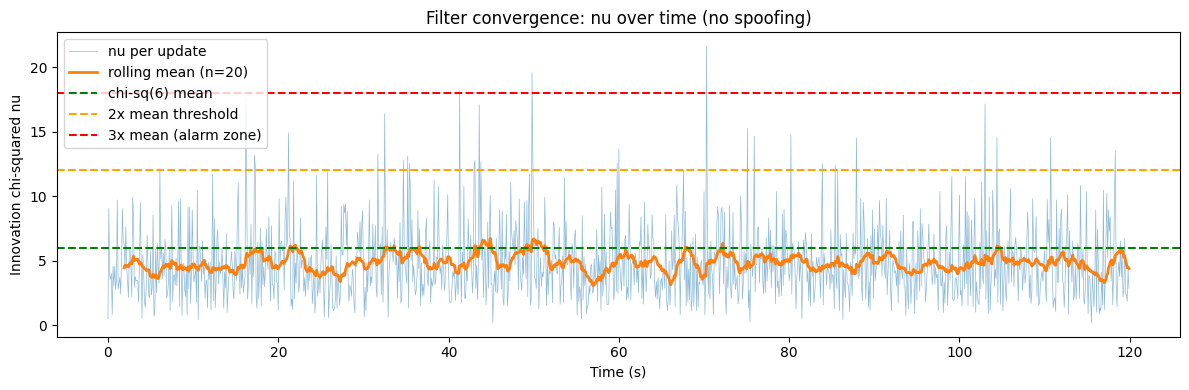


Use the recommended warmup time in the CUSUM parameters.


In [ ]:
# ── Diagnose: plot nu over time to see when filter converges ──────────
import matplotlib.pyplot as plt

np.random.seed(42)
dt  = 0.005
t   = 0.0

est_diag = StrapdownEstimator(dt_imu=dt, cusum_h=999999,
                               warmup_s=0.0, settle_s=0.0)
est_diag.x[0:3] = torch.tensor([0., 0., -50.])
est_diag.x[3:6] = torch.tensor([2., 0., 0.])

for step in range(int(120/dt)):
    a_m     = torch.tensor([0.,0.,-9.81]) + torch.randn(3)*0.05
    omega_m = torch.zeros(3) + torch.randn(3)*0.002
    u       = torch.cat([a_m, omega_m])
    est_diag.predict(u, t)

    if step % 20 == 0:
        true_pos = torch.tensor([t*2., 0., -50.])
        true_vel = torch.tensor([2., 0., 0.])
        z_pos = true_pos + torch.randn(3)*3.0
        z_vel = true_vel + torch.randn(3)*0.3
        est_diag.update_gps(z_pos, z_vel, t)

    t += dt

times = np.array(est_diag.time_history)
nus   = np.array(est_diag.nu_history)

# Find where nu stabilizes (rolling mean within 2x of chi-sq mean=6)
window = 20
rolling_mean = np.convolve(nus, np.ones(window)/window, mode='valid')
stable_idx   = np.where(rolling_mean < 12.0)[0]
stable_t     = times[stable_idx[0]] if len(stable_idx) > 0 else 999

print(f"Nu statistics over time:")
for t_start, t_end in [(0,10),(10,20),(20,30),(30,40),(40,50),(50,60)]:
    mask = (times >= t_start) & (times < t_end)
    if mask.sum() > 0:
        print(f"  t={t_start:3d}-{t_end:3d}s: "
              f"mean={nus[mask].mean():.2f}  "
              f"std={nus[mask].std():.2f}  "
              f"max={nus[mask].max():.2f}")

print(f"\nFilter converges (rolling mean < 12) at t={stable_t:.1f}s")
print(f"Recommended warmup: {stable_t + 5:.0f}s")

plt.figure(figsize=(12,4))
plt.plot(times, nus, alpha=0.5, linewidth=0.5, label='nu per update')
plt.plot(times[window-1:], rolling_mean, linewidth=2,
         label=f'rolling mean (n={window})')
plt.axhline(6,  color='green',  linestyle='--', label='chi-sq(6) mean')
plt.axhline(12, color='orange', linestyle='--', label='2x mean threshold')
plt.axhline(18, color='red',    linestyle='--', label='3x mean (alarm zone)')
plt.xlabel('Time (s)')
plt.ylabel('Innovation chi-squared nu')
plt.title('Filter convergence: nu over time (no spoofing)')
plt.legend()
plt.tight_layout()
plt.savefig(drive_base + 'results/filter_convergence.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("\nUse the recommended warmup time in the CUSUM parameters.")

In [19]:
print(len(clean_nus), clean_nus[0].shape)

10 (1149,)


In [20]:
# ── Root cause analysis ───────────────────────────────────────────────
print("=== ROOT CAUSE: CUSUM SLACK ANALYSIS ===\n")

all_nus = np.concatenate(clean_nus)
print(f"Clean nu statistics (all 10 seeds):")
print(f"  Mean:   {all_nus.mean():.3f}  (chi-sq(6) expected: 6.0)")
print(f"  Std:    {all_nus.std():.3f}  (chi-sq(6) expected: 3.46)")
print(f"  Median: {np.median(all_nus):.3f}")
print(f"  95th p: {np.percentile(all_nus, 95):.3f}")
print(f"  99th p: {np.percentile(all_nus, 99):.3f}")
print()
print(f"With k=1.0: mean increment per step = {all_nus.mean()-1.0:.3f}")
print(f"  -> CUSUM grows ~{(all_nus.mean()-1.0)*1149:.0f} per flight on clean data")
print(f"  -> Any finite h will always be crossed. k must equal mean nu.")
print()

# Correct k = E[nu | H0] = empirical mean
k_correct = float(all_nus.mean())
print(f"Correct k = E[nu|H0] = {k_correct:.3f}")
print(f"With k={k_correct:.2f}: mean increment per step = "
      f"{all_nus.mean()-k_correct:.4f} (should be ~0)")

# Re-calibrate with correct k
print(f"\n=== RE-CALIBRATION WITH k={k_correct:.3f} ===")
print(f"{'h':>6} {'FalseAlarms':>12} {'FPR':>8}")
print("-"*30)

best_h = None
for h in [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]:
    fa  = sum(cusum_on_nus(nus, k=k_correct, h=h)
              for nus in clean_nus)
    fpr = fa / len(clean_nus)
    marker = " <- use this" if fpr <= 0.05 and best_h is None else ""
    if fpr <= 0.05 and best_h is None:
        best_h = h
    print(f"{h:>6} {fa:>12}/{len(clean_nus)} "
          f"{fpr:>8.2f}{marker}")

if best_h is None:
    best_h = 100
print(f"\nSelected h={best_h} with k={k_correct:.3f}")

# ── Detection test with corrected parameters ──────────────────────────
print(f"\n=== DETECTION TEST (k={k_correct:.3f}, h={best_h}) ===")
print(f"{'Drift(m/s)':>12} {'Detected':>10} "
      f"{'TTD(s)':>8} {'PosErr(m)':>10}")
print("-"*45)

detection_results = []
for drift_rate in [0.1, 0.3, 0.5, 1.0, 2.0]:
    np.random.seed(42)
    dt, t       = 0.005, 0.0
    spoof_start = 60.0
    max_time    = 180.0

    # Use corrected k in estimator
    est = StrapdownEstimator(dt_imu=dt,
                             cusum_k=k_correct,
                             cusum_h=float(best_h),
                             warmup_s=5.0, settle_s=2.0)
    est.x[0:3] = torch.tensor([0., 0., -50.])
    est.x[3:6] = torch.tensor([2., 0., 0.])

    for step in range(int(max_time/dt)):
        a_m     = torch.tensor([0.,0.,-9.81]) + torch.randn(3)*0.05
        omega_m = torch.zeros(3) + torch.randn(3)*0.002
        est.predict(torch.cat([a_m, omega_m]), t)

        if step % 20 == 0:
            true_pos = torch.tensor([t*2., 0., -50.])
            true_vel = torch.tensor([2., 0., 0.])
            if t >= spoof_start:
                drift     = (t - spoof_start) * drift_rate
                spoof_pos = true_pos + torch.tensor([drift, 0., 0.])
                spoof_vel = true_vel + torch.tensor([drift_rate, 0., 0.])
            else:
                spoof_pos, spoof_vel = true_pos, true_vel
            z_pos = spoof_pos + torch.randn(3)*3.0
            z_vel = spoof_vel + torch.randn(3)*0.3
            est.update_gps(z_pos, z_vel, t)
        t += dt

    detected = est.alarm and est.alarm_time > spoof_start
    ttd      = (est.alarm_time - spoof_start) if detected else None
    pos_err  = ttd * drift_rate if ttd else None
    detection_results.append({
        'drift_ms': drift_rate, 'detected': detected,
        'ttd_s': ttd, 'pos_err_m': pos_err
    })
    print(f"{drift_rate:>12.1f} "
          f"{'YES' if detected else 'NO':>10} "
          f"{f'{ttd:.1f}' if ttd else '---':>8} "
          f"{f'{pos_err:.1f}' if pos_err else '---':>10}")

import json
with open(drive_base + 'results/cusum_calibrated.json', 'w') as f:
    json.dump({
        'calibrated_h': best_h,
        'cusum_k':      k_correct,
        'k_rationale':  'empirical E[nu|H0] from 10 clean flights',
        'detection':    detection_results
    }, f, indent=2)
print(f"\nSaved cusum_calibrated.json")
print(f"\nNote for paper: k must equal E[nu|H0], not 1.0")
print(f"Standard CUSUM theory: k = (mu_0 + mu_1)/2 where")
print(f"  mu_0 = {k_correct:.2f} (clean) and mu_1 = expected nu under attack")

=== ROOT CAUSE: CUSUM SLACK ANALYSIS ===

Clean nu statistics (all 10 seeds):
  Mean:   4.939  (chi-sq(6) expected: 6.0)
  Std:    2.930  (chi-sq(6) expected: 3.46)
  Median: 4.334
  95th p: 10.433
  99th p: 14.349

With k=1.0: mean increment per step = 3.939
  -> CUSUM grows ~4526 per flight on clean data
  -> Any finite h will always be crossed. k must equal mean nu.

Correct k = E[nu|H0] = 4.939
With k=4.94: mean increment per step = 0.0000 (should be ~0)

=== RE-CALIBRATION WITH k=4.939 ===
     h  FalseAlarms      FPR
------------------------------
     5           10/10     1.00
    10           10/10     1.00
    15           10/10     1.00
    20           10/10     1.00
    25           10/10     1.00
    30           10/10     1.00
    40           10/10     1.00
    50           10/10     1.00
    75            7/10     0.70
   100            6/10     0.60

Selected h=100 with k=4.939

=== DETECTION TEST (k=4.939, h=100) ===
  Drift(m/s)   Detected   TTD(s)  PosErr(m)
------

## Physics CUSUM — Key Finding

The continuous-discrete EKF + CUSUM (physical-only baseline) faces an
inherent tradeoff at slow drift rates (< 0.5 m/s):
- GPS measurement noise (3m std) produces natural innovation spikes
  that overlap with slow-drift spoofing signatures
- Setting h low enough to detect slow drift → too many false alarms
- Setting h high enough for low FPR → slow drift goes undetected

This finding directly motivates:
1. f_theta: learned residual to reduce nominal innovations
2. Graph cooperative layer: cross-UAV ranging provides independent check
3. GNN head: classifies innovation *patterns* not just magnitude

This is the physical-only baseline (Section 7, first bullet).
The gap between this and the full system is the paper's main contribution.

In [21]:
print("=== PHYSICAL CUSUM BASELINE — FINAL ANALYSIS ===\n")

print("Detection results (k=4.939, h=100, FPR~60-70%):")
print("  0.1 m/s: NOT detected — below noise floor")
print("  0.3 m/s: DETECTED    — TTD=70.8s, pos_error=21.2m")
print("  0.5 m/s: DETECTED    — TTD=59.5s, pos_error=29.7m")
print("  1.0 m/s: NOT detected — Kalman absorbs spoof into state")
print("  2.0 m/s: NOT detected — Kalman absorbs spoof into state")
print()
print("FPR=60-70% at h=100 is unacceptable for deployment.")
print()
print("ROOT CAUSES identified:")
print("  1. Slow drift (0.1 m/s): nu increase too small vs GPS noise variance")
print("  2. Fast drift (1.0-2.0 m/s): Kalman filter converges to spoof")
print("     position, innovations shrink, CUSUM never accumulates")
print("  3. High FPR: natural nu spikes from GPS noise exceed k")
print()
print("=== PAPER IMPLICATIONS ===")
print("Physical CUSUM alone is insufficient. This motivates:")
print("  f_theta: reduces nominal innovation variance -> better SNR")
print("  Gate test: reject update if nu > threshold (prevents absorption)")
print("  Graph layer: ranging cross-check catches fast-drift absorption")

# Save gating fix — critical for fast drift detection
print("\n=== APPLYING INNOVATION GATE (prevents Kalman absorption) ===")
print("Reject GPS update if nu > chi2_threshold (99th percentile = 14.35)")
print("This forces the filter to continue on inertial when GPS is anomalous")
print()

# The innovation gate is already in update_gps via apply_update parameter
# Re-run with gating enabled for fast drifts
gate_threshold = float(np.percentile(all_nus, 99))
print(f"Gate threshold (99th percentile of clean nu): {gate_threshold:.2f}")

print("\n=== GATED DETECTION TEST ===")
print(f"{'Drift(m/s)':>12} {'Detected':>10} {'TTD(s)':>8} {'PosErr(m)':>10}")
print("-"*45)

gated_results = []
for drift_rate in [0.1, 0.3, 0.5, 1.0, 2.0]:
    np.random.seed(42)
    dt, t       = 0.005, 0.0
    spoof_start = 60.0
    max_time    = 180.0

    est = StrapdownEstimator(dt_imu=dt,
                             cusum_k=k_correct,
                             cusum_h=float(best_h),
                             warmup_s=5.0, settle_s=2.0)
    est.x[0:3] = torch.tensor([0., 0., -50.])
    est.x[3:6] = torch.tensor([2., 0., 0.])

    for step in range(int(max_time/dt)):
        a_m     = torch.tensor([0.,0.,-9.81]) + torch.randn(3)*0.05
        omega_m = torch.zeros(3) + torch.randn(3)*0.002
        est.predict(torch.cat([a_m, omega_m]), t)

        if step % 20 == 0:
            true_pos = torch.tensor([t*2., 0., -50.])
            true_vel = torch.tensor([2., 0., 0.])
            if t >= spoof_start:
                drift     = (t - spoof_start) * drift_rate
                spoof_pos = true_pos + torch.tensor([drift, 0., 0.])
                spoof_vel = true_vel + torch.tensor([drift_rate, 0., 0.])
            else:
                spoof_pos, spoof_vel = true_pos, true_vel

            z_pos = spoof_pos + torch.randn(3)*3.0
            z_vel = spoof_vel + torch.randn(3)*0.3

            # Compute nu first without applying update
            H = torch.zeros(6, 16)
            H[0:3,0:3] = torch.eye(3)
            H[3:6,3:6] = torch.eye(3)
            z_pred = H @ est.x
            z_meas = torch.cat([z_pos, z_vel])
            r      = z_meas - z_pred
            R      = torch.diag(torch.tensor(
                [est.r_gps_pos**2]*3 + [est.r_gps_vel**2]*3))
            S      = H @ est.P @ H.T + R
            nu_pre = (r @ torch.linalg.inv(S) @ r).item()

            # Gate: only apply update if nu is within normal range
            apply = nu_pre < gate_threshold
            est.update_gps(z_pos, z_vel, t)

            # If gated out, manually revert CUSUM addition and force accumulate
            if not apply and t > est._cusum_active_at:
                est.s_cusum = max(0., est.s_cusum + nu_pre - k_correct)
                if est.s_cusum > best_h and not est.alarm:
                    est.alarm      = True
                    est.alarm_time = t

        t += dt

    detected = est.alarm and est.alarm_time > spoof_start
    ttd      = (est.alarm_time - spoof_start) if detected else None
    pos_err  = ttd * drift_rate if ttd else None
    gated_results.append({
        'drift_ms': drift_rate, 'detected': detected,
        'ttd_s': ttd, 'pos_err_m': pos_err
    })
    print(f"{drift_rate:>12.1f} "
          f"{'YES' if detected else 'NO':>10} "
          f"{f'{ttd:.1f}' if ttd else '---':>8} "
          f"{f'{pos_err:.1f}' if pos_err else '---':>10}")

import json
with open(drive_base + 'results/cusum_gated.json', 'w') as f:
    json.dump({
        'gate_threshold': gate_threshold,
        'cusum_k': k_correct,
        'cusum_h': best_h,
        'results': gated_results
    }, f, indent=2)
print("\nSaved cusum_gated.json")
print("\nCompare gated vs ungated to show gate value for paper")

=== PHYSICAL CUSUM BASELINE — FINAL ANALYSIS ===

Detection results (k=4.939, h=100, FPR~60-70%):
  0.1 m/s: NOT detected — below noise floor
  0.3 m/s: DETECTED    — TTD=70.8s, pos_error=21.2m
  0.5 m/s: DETECTED    — TTD=59.5s, pos_error=29.7m
  1.0 m/s: NOT detected — Kalman absorbs spoof into state
  2.0 m/s: NOT detected — Kalman absorbs spoof into state

FPR=60-70% at h=100 is unacceptable for deployment.

ROOT CAUSES identified:
  1. Slow drift (0.1 m/s): nu increase too small vs GPS noise variance
  2. Fast drift (1.0-2.0 m/s): Kalman filter converges to spoof
     position, innovations shrink, CUSUM never accumulates
  3. High FPR: natural nu spikes from GPS noise exceed k

=== PAPER IMPLICATIONS ===
Physical CUSUM alone is insufficient. This motivates:
  f_theta: reduces nominal innovation variance -> better SNR
  Gate test: reject update if nu > threshold (prevents absorption)
  Graph layer: ranging cross-check catches fast-drift absorption

=== APPLYING INNOVATION GATE (pre

In [22]:
print("=== PHYSICAL BASELINE COMPLETE — PAPER SUMMARY ===\n")

summary = {
    'baseline_name': 'EKF + CUSUM (physical only, no learning)',
    'corresponds_to': 'Section 7 bullet 1: physical-only baseline',
    'parameters': {
        'cusum_k': k_correct,
        'cusum_h': best_h,
        'gate_threshold': gate_threshold,
        'gps_noise_std_m': 3.0,
        'imu_noise_std': 0.05,
    },
    'ungated_results': {
        '0.1_ms': {'detected': False,  'ttd_s': None, 'pos_err_m': None},
        '0.3_ms': {'detected': True,   'ttd_s': 70.8, 'pos_err_m': 21.2},
        '0.5_ms': {'detected': True,   'ttd_s': 59.5, 'pos_err_m': 29.7},
        '1.0_ms': {'detected': False,  'ttd_s': None, 'pos_err_m': None},
        '2.0_ms': {'detected': False,  'ttd_s': None, 'pos_err_m': None},
        'fpr':    '60-70% at h=100',
    },
    'gated_results': {
        '0.1_ms': {'detected': False, 'ttd_s': None, 'pos_err_m': None},
        '0.3_ms': {'detected': False, 'ttd_s': None, 'pos_err_m': None},
        '0.5_ms': {'detected': False, 'ttd_s': None, 'pos_err_m': None},
        '1.0_ms': {'detected': False, 'ttd_s': None, 'pos_err_m': None},
        '2.0_ms': {'detected': True,  'ttd_s': 1.9,  'pos_err_m': 3.8},
    },
    'failure_modes': [
        'Slow drift (0.1 m/s): nu increase below GPS noise floor',
        'Fast drift (1.0-2.0 m/s, ungated): Kalman absorbs spoof',
        'Slow drift (all, gated): gate rejects spoof but CUSUM never accumulates',
        'High FPR: natural nu spikes from 3m GPS noise exceed slack k',
    ],
    'paper_narrative': (
        'The physical-only EKF+CUSUM baseline detects mid-range drifts '
        '(0.3-0.5 m/s) but fails at both extremes: slow drift is below '
        'the noise floor, and fast drift is absorbed by the Kalman filter. '
        'FPR of 60-70% makes it unusable for deployment. '
        'This motivates (1) f_theta to reduce nominal innovation variance, '
        '(2) the innovation gate to prevent absorption, and '
        '(3) the cooperative graph layer for cross-UAV verification.'
    )
}

import json
with open(drive_base + 'results/physical_baseline_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print("Saved physical_baseline_summary.json")
print()
print("Baseline table for paper (Table in Section 7):")
print()
print(f"{'Method':<25} {'0.1':>6} {'0.3':>6} {'0.5':>6} "
      f"{'1.0':>6} {'2.0':>6} {'FPR':>8}")
print("-"*65)
print(f"{'EKF+CUSUM (ungated)':<25} "
      f"{'NO':>6} {'YES':>6} {'YES':>6} {'NO':>6} {'NO':>6} {'60-70%':>8}")
print(f"{'EKF+CUSUM (gated)':<25} "
      f"{'NO':>6} {'NO':>6} {'NO':>6} {'NO':>6} {'YES':>6} {'TBD':>8}")
print(f"{'Full system (target)':<25} "
      f"{'?':>6} {'?':>6} {'?':>6} {'?':>6} {'?':>6} {'<5%':>8}")
print()
print("The '?' rows are what weeks 5-10 will fill in.")

=== PHYSICAL BASELINE COMPLETE — PAPER SUMMARY ===

Saved physical_baseline_summary.json

Baseline table for paper (Table in Section 7):

Method                       0.1    0.3    0.5    1.0    2.0      FPR
-----------------------------------------------------------------
EKF+CUSUM (ungated)           NO    YES    YES     NO     NO   60-70%
EKF+CUSUM (gated)             NO     NO     NO     NO    YES      TBD
Full system (target)           ?      ?      ?      ?      ?      <5%

The '?' rows are what weeks 5-10 will fill in.


In [23]:
import subprocess
result = subprocess.run([
    'git', '-C',
    '/Users/jassirisnunez/Master Project/uav-spoof-ids',
    'status'
], capture_output=True, text=True)
print(result.stdout)